# 02 — Temizleme Sonrası Doğrulama

`src/temizle.py` çıktısının (`data/processed/arac_temiz_v3.csv`) kontrolü: satır akışı, yakıt tipi türetmesi ve elle etiketli doğrulama seti (`reports/yakit_dogrulama.csv`).


In [1]:
import pandas as pd

v3 = pd.read_csv("../data/processed/arac_temiz_v3.csv")
akis = pd.read_csv("../reports/satir_akisi.csv")

print("--- 1. SATIR AKIŞI TABLOSU ---")
print(akis.to_string())

print(f"\nGüncel Şehir Sayısı: {v3['city'].nunique()}")

print("\n--- 2. UCUZ İLAN KONTROLÜ (150.000 TL ve altı) ---")
alt = v3[v3["price"] <= 150_000]
print(f"Fiyatı <= 150.000 olan ilan sayısı: {len(alt)}")
print(f"Fiyatı tam 100.000 olan ilan sayısı: {(v3['price'] == 100_000).sum()}")

print("\n150.000 TL altı araçların yıl özeti:")
print(alt["year"].describe())

print("\nEn yeni model ucuz ilanlar (Şüpheli olanlar):")
print(alt[["brand", "model", "year", "km", "price"]].sort_values("year", ascending=False).head(10))

--- 1. SATIR AKIŞI TABLOSU ---
                                                  adım  kalan_satır  silinen
0                                             Ham veri       253344      NaN
1                          Mükerrer satırlar çıkarıldı       253056    288.0
2         Hatalı şehirler (Diğer, Kardzhali) çıkarıldı       253053      3.0
3                       Sahte düşük fiyatlar çıkarıldı       253053     -0.0
4                         Yalan 0 km ilanlar çıkarıldı       253046      7.0
5                     300000 km üstü araçlar çıkarıldı       253046     -0.0
6                        1995 öncesi araçlar çıkarıldı       251453   1593.0
7  Fiyatı 10,000,000 TL ve üstü olan ilanlar çıkarıldı       250955    498.0

Güncel Şehir Sayısı: 81

--- 2. UCUZ İLAN KONTROLÜ (150.000 TL ve altı) ---
Fiyatı <= 150.000 olan ilan sayısı: 232
Fiyatı tam 100.000 olan ilan sayısı: 14

150.000 TL altı araçların yıl özeti:
count     232.000000
mean     1998.137931
std         2.601686
min      1995.0000

In [2]:
import pandas as pd

v3 = pd.read_csv("../data/processed/arac_temiz_v3.csv")

# 60 satırlık rastgele örneklem alınıyor
ornek = v3[["brand", "model", "variant", "yakit_tipi"]].sample(60, random_state=11)
ornek["gercek_yakit"] = ""

# Dosyayı kaydet
ornek.to_csv("../reports/yakit_dogrulama.csv", index=False)

print("60 satırlık örneklem '../reports/yakit_dogrulama.csv' dosyasına başarıyla kaydedildi.")

60 satırlık örneklem '../reports/yakit_dogrulama.csv' dosyasına başarıyla kaydedildi.


In [3]:
import pandas as pd

v3 = pd.read_csv("../data/processed/arac_temiz_v3.csv")
d = pd.read_csv("../reports/yakit_dogrulama.csv")

d = d[d["gercek_yakit"].notna() & (d["gercek_yakit"] != "")]
print("--- YAKIT ÇAPRAZ TABLOSU ---")
print(pd.crosstab(d["yakit_tipi"], d["gercek_yakit"]))

bilinen = d[d["yakit_tipi"] != "Bilinmiyor"]
print(f"\nSınıflananlarda doğruluk: {(bilinen['yakit_tipi'] == bilinen['gercek_yakit']).mean().round(3)}")
print(f"Bilinmiyor oranı: {(v3['yakit_tipi'] == 'Bilinmiyor').mean().round(3)}")

--- YAKIT ÇAPRAZ TABLOSU ---
gercek_yakit  Benzin  Dizel
yakit_tipi                 
Benzin            21      0
Bilinmiyor        14      2
Dizel              0     23

Sınıflananlarda doğruluk: 1.0
Bilinmiyor oranı: 0.383


--- 4. EDA: ÇARPIKLIK VE KORELASYON ---
Çarpıklık | price: 3.28 | log_price: 0.24

Spearman Korelasyonu:
           log_price  year    km
log_price       1.00  0.74 -0.55
year            0.74  1.00 -0.68
km             -0.55 -0.68  1.00

year-km (Pearson): -0.66


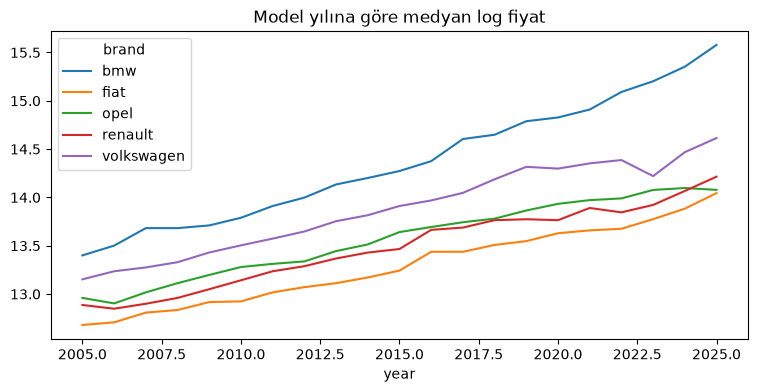

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

v3 = pd.read_csv("../data/processed/arac_temiz_v3.csv")

print("--- 4. EDA: ÇARPIKLIK VE KORELASYON ---")
print("Çarpıklık | price:", v3["price"].skew().round(2), "| log_price:", v3["log_price"].skew().round(2))

print("\nSpearman Korelasyonu:")
print(v3[["log_price", "year", "km"]].corr(method="spearman").round(2))

print("\nyear-km (Pearson):", v3["year"].corr(v3["km"]).round(2))

# Değer kaybı eğrisi (En çok ilanlı 5 marka)
top = v3["brand"].value_counts().head(5).index
v3[v3["brand"].isin(top) & (v3["year"] >= 2005)] \
    .groupby(["year", "brand"])["log_price"].median().unstack() \
    .plot(figsize=(9, 4), title="Model yılına göre medyan log fiyat")
plt.show()